# CIS I — Assignment 1: Pivot Calibration

This notebook walks through the pivot-calibration scenario from the
assignment (Figure 1): a pointer and a calibration object, each
carrying a marker body, observed by an optical tracker. Your job is to
**design** the marker-sphere layouts and workspace placements, then
**calibrate** the pointer's tip position `p_tip` to within about 2mm.

Everything runs against `src.simulation`, a self-contained simulator that plays the role of the physical tracker +
hand-guided robot + calibration sensor described in the handout. It injects measurement noise — your code never sees ground truth
except where explicitly noted for **validation/reporting** in Step 8 (real
hardware wouldn't give you that; the point there is to report your achieved
accuracy, not to use the ground truth in your calibration math itself).



In [ ]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

import numpy as np
from src import simulation
from src import vct3, Rot, Frame

#SEED = 46
#np.random.seed(SEED)

np.set_printoptions(precision=3, suppress=True)


## Step 1: Design the pointer's marker body

Choose approximate local marker-sphere positions `a_ptr,k` (a `List[vct3]`,
relative to the pointer's own coordinate frame) and the pointer tip's
approximate local position `p_tip_approx`. These are your
*nominal design values* — the simulator will independently perturb the
*actual* manufactured positions by a small, noise amount (bounded at
2mm).


In [1172]:
ptr_local_positions = [
    vct3(0,0,0),
    vct3(50,0,0),
    vct3(0,80,0),
    vct3(0,0,60)

]
ptr_tip_approx = vct3(0,0,-150)  # TODO: vct3, the tip's approximate position in the pointer's local frame


## Step 1.1: Design the calibration object's marker body

Same idea, for the calibration object's local marker positions `a_cal,k`.


In [1173]:
cal_local_positions = [
    vct3(400,-200,0),
    vct3(400,200,0),
    vct3(-400,-200,0),
    vct3(-400,200,0)
]


## Step 2: Approximate workspace poses

Specify approximate poses (as `Frame` class from src) for the tracking camera
(`F_tracker`) and the calibration object (`F_cal`), relative to the
workspace. The tracker's usable volume is the tetrahedral region in the
handout's Figure 2 (roughly 100-200cm in front of the tracker, widening
from ~120cm to ~200cm across) — place the calibration object, and later
the pointer, so they're inside that volume.


In [1174]:
F_tracker_approx = Frame(
    Rot.eye(),
    vct3(-1100, 300, 300)
)

F_cal_approx = Frame(
    Rot.eye(),
    vct3(650, -200, 300)
)

## Step 3: Build the simulation

Fully provided — this just wires up your Step 1/2 design choices through
`simulation`'s `DefineMarkerBody` / `PlaceMarkerBody` / `CreateTracker`
equivalents. `ptr_placed`/`cal_placed` are `PlacedBody` handles: each pairs
a `MarkerBody` with its hidden actual placement, and gets passed to
`simulation.sample_marker_bodies(...)` whenever you want a reading.


In [1175]:
ptr_mb = simulation.define_marker_body("ptr_mb", ptr_local_positions)
cal_mb = simulation.define_marker_body("cal_mb", cal_local_positions)

cal_placed = simulation.place_marker_body(cal_mb, F_cal_approx)
# The pointer's own body doesn't have a meaningful "workspace placement" yet
# It moves every time it's hand-guided (Step 4-6). 
# precision="precise" matches a robot-controlled pose rather than a coarsely, manually placed
# static object (see place_marker_body's docstring).
ptr_placed = simulation.place_marker_body(ptr_mb, Frame.eye(), precision="precise")

ptr = simulation.define_pointer("ptr1", ptr_tip_approx, ptr_mb)
trk = simulation.create_tracker("trk1", F_tracker_approx)

print("simulation built:", ptr_mb.name, cal_mb.name, ptr.name, trk.name)


simulation built: ptr_mb cal_mb ptr1 trk1


## Step 3.1: Refine `a_ptr,k` / `a_cal,k`

> "Observations of marker positions can be used to determine accurate
> estimates of relative positions a_ptr,k of markers on pointer and
> calibration objects... **Hint**: You probably want to take multiple
> readings in order to reduce the uncertainty associated with the a_k
> values."


In [1176]:
def refine_marker_body(trk, placed, n_readings=30, passes=3):
    
#calibration body samples
    for i in range(passes):

        reading_a_values = []

        for j in range(n_readings):
            readings = simulation.sample_marker_bodies(
                    trk,
                    [placed]
                )
            F_inv = readings[placed.body.name].frame.inv()
            obs_b = readings[placed.body.name].markers
            new_a_positions = []

            for marker in obs_b:
                b = marker.p
                a = F_inv * b

                new_a_positions.append([a.x, a.y, a.z])

            reading_a_values.append(new_a_positions)

        # Stack all 30 readings
        stacked = np.stack(reading_a_values)

        # Calculating mean column by column
        mean_a = np.mean(stacked, axis=0)

        # Convert back to vct3 objects
        mean_positions = [
                    vct3(*row)
                    for row in mean_a
                ]

                # Update marker body positions
        placed.body.set_marker_positions(mean_positions)
refine_marker_body(trk, ptr_placed)
refine_marker_body(trk, cal_placed)

## Steps 4-6: Collect pivot-calibration observations

For each observation `j`: hand-guide the pointer near the calibration
object at some desired orientation `R_desired,j`, take one simultaneous
tracker reading of *both* bodies, and read the calibration sensor. Loop
skeleton is provided; you choose how many observations to take, how to
vary `R_desired,j`, and what to do when the calibration sensor reports the
tip as out of range (`sense_tip` returns `None`).


In [1177]:
N_OBSERVATIONS = 30  # TODO

def rotation_distance_deg(R1, R2):

    # Calculate relative rotation matrix
    R_relative = R1.matrix.T @ R2.matrix

    # Calculate relative rotation angle
    cos_theta = (np.trace(R_relative) - 1) / 2

    # Avoid numerical errors
    cos_theta = np.clip(cos_theta, -1.0, 1.0)

    theta = np.arccos(cos_theta)

    return np.degrees(theta)

min_angle_diff = 25.0
rng = np.random.default_rng(42)

accepted_rotations = []
accepted_angles = []

F_ptr_list = []
F_cal_list = []
sensed_tip_list = []
for j in range(N_OBSERVATIONS):

    while True:

        # 1. Generate random XYZ Euler angles
        rx = int(rng.integers(-70, 71))
        ry = int(rng.integers(-70, 71))
        rz = int(rng.integers(-70, 71))

        R_desired = Rot.xyz_deg(rx, ry, rz)  

        too_close = False

        for R_old in accepted_rotations:
            distance = rotation_distance_deg(R_desired, R_old)

            if distance < min_angle_diff:
                too_close = True
                break

        if too_close:
            continue

        hg = simulation.hand_guide_pointer(ptr, ptr_placed, cal_placed, R_desired)
        obs = simulation.sample_marker_bodies(trk, [ptr_placed, cal_placed])
        sensed = simulation.sense_tip(ptr, hg)

        if sensed is None:
            continue

        F_ptr_list.append(obs["ptr_mb"].frame)
        F_cal_list.append(obs["cal_mb"].frame)
        sensed_tip_list.append(sensed)

        accepted_rotations.append(R_desired)
        accepted_angles.append((rx, ry, rz))

        break


print(f"collected {len(F_ptr_list)} observations")


collected 30 observations


`sensed_tip_list` holds each observation's high-accuracy calibration-sensor
reading `p_sensed,j`: the pointer tip's position relative to the
calibration object's coordinate system, measured to negligible error (or
`None` if that observation ended up outside the sensor's 5mm range). The
hand-guided tip only lands *approximately* at the calibration object's
origin, so the sensor tells you exactly where it actually was for each
observation — an input to Step 7, together with `F_ptr,j` and `F_cal,j`.


## Step 7: Compute a calibrated value for `p_tip`

This is the assignment's core deliverable — implement it yourself and specify the details of implementation in the report.

Each observation `j` gives you three measurements of the same physical
moment: `F_ptr,j` and `F_cal,j` from the tracker, and `p_sensed,j` from the
calibration sensor. Derive how they relate to the unknown `p_tip`, and use
all three in your calibration.

**Corner case to consider**: What are the corner cases you want to analyse here? (e.g. what happens to observations whose `p_sensed,j` is `None`?)

**Minimum data**: how many observations, and what about their rotations,
are needed for the stacked system to actually be solvable? How do you define whether a system is solvable here? Include that in your report


In [1178]:
def compute_pivot_calibration(F_ptr_list, F_cal_list, sensed_tip_list):

    # # 1. Check inputs
    # if not (len(F_ptr_list) == len(F_cal_list) == len(sensed_tip_list)):
    #     raise ValueError("Input lists must have the same length")

    A_list = []
    b_list = []

    # 2. Build the least-squares system
    for j in range(len(F_ptr_list)):

        F_ptr = F_ptr_list[j]
        F_cal = F_cal_list[j]
        p_sensed = sensed_tip_list[j]

        # Skip invalid sensor measurements
        if p_sensed is None:
            continue

        R_ptr = F_ptr.R.matrix
        R_cal = F_cal.R.matrix

        t_ptr = F_ptr.p.vec.ravel()
        t_cal = F_cal.p.vec.ravel()
        p_s = p_sensed.vec.ravel()

        # R_ptr * p_tip = R_cal * p_sensed + t_cal - t_ptr
        A_j = R_ptr
        b_j = R_cal @ p_s + t_cal - t_ptr

        A_list.append(A_j)
        b_list.append(b_j)

    # 3. Check valid observations
    if len(A_list) == 0:
        raise ValueError("No valid sensor observations")

    # 4. Stack the equations
    A = np.vstack(A_list)
    b = np.concatenate(b_list)

    # 5. Least-squares solution
    x, residuals, rank, s = np.linalg.lstsq(A, b, rcond=None)

    # if rank < 3:
    #     raise ValueError("Calibration system is rank deficient")

    p_tip = vct3(*x)

    # 6. Calculate covariance
    residual_vector = A @ x - b
    dof = len(b) - rank

    if dof > 0:
        sigma_squared = np.sum(residual_vector ** 2) / dof
        cov_tip = sigma_squared * np.linalg.pinv(A.T @ A)
    else:
        # One observation cannot estimate variance from residuals
        cov_tip = np.full((3, 3), np.nan)

    print("Valid observations:", len(A_list))
    print("Matrix A shape:", A.shape)
    print("Matrix rank:", rank)

    return p_tip, cov_tip


p_tip_est, p_tip_cov = compute_pivot_calibration(
    F_ptr_list,
    F_cal_list,
    sensed_tip_list
)


p_tip_est, p_tip_cov = compute_pivot_calibration(F_ptr_list, F_cal_list, sensed_tip_list)


Valid observations: 30
Matrix A shape: (90, 3)
Matrix rank: 3
Valid observations: 30
Matrix A shape: (90, 3)
Matrix rank: 3


In [1179]:
print("calibrated p_tip:", p_tip_est)
print("estimated covariance (mm^2):\n", p_tip_cov)
print("estimated std-dev per axis (mm):", np.sqrt(np.diag(p_tip_cov)))


calibrated p_tip: vct3(x=0.70, y=3.25, z=-149.63)
Internal Vector:
[[   0.703]
 [   3.25 ]
 [-149.628]]
estimated covariance (mm^2):
 [[ 0.001  0.    -0.   ]
 [-0.     0.001  0.   ]
 [ 0.    -0.     0.001]]
estimated std-dev per axis (mm): [0.029 0.029 0.029]


In [1180]:
print("Valid sensor readings:", len(sensed_tip_list))
print("Invalid readings:", sum(s is None for s in sensed_tip_list))

# Ground truth ONLY for debugging
p_tip_true = ptr.get_actual_tip_position().p

calibration_error = (p_tip_est - p_tip_true).norm()

print(f"Tip calibration error: {calibration_error:.4f} mm")

Valid sensor readings: 30
Invalid readings: 0
Tip calibration error: 2.2361 mm


In [1181]:
validation_residuals = []

for j in range(10):

    # New calibration pose
    R_desired = Rot.xyz_deg(
        -50 + 10*j,
        30 - 5*j,
        -40 + 8*j
    )

    hg = simulation.hand_guide_pointer(
        ptr, ptr_placed, cal_placed, R_desired
    )

    obs = simulation.sample_marker_bodies(
        trk, [ptr_placed, cal_placed]
    )

    sensed = simulation.sense_tip(ptr, hg)

    if sensed is None:
        continue

    F_ptr = obs["ptr_mb"].frame
    F_cal = obs["cal_mb"].frame

    # Predict tip in calibration frame
    p_sensed_pred = F_cal.inv() * F_ptr * p_tip_est

    # Compare with actual sensor reading
    error = (p_sensed_pred - sensed).norm()

    validation_residuals.append(error)

print("Valid held-out readings:", len(validation_residuals))

if validation_residuals:
    print(
        "Held-out calibration mean error:",
        np.mean(validation_residuals),
        "mm"
    )
    print(
        "Held-out calibration max error:",
        np.max(validation_residuals),
        "mm"
    )

Valid held-out readings: 10
Held-out calibration mean error: 0.22069766191824414 mm
Held-out calibration max error: 0.35508588243308975 mm


## Step 8: Validate against test poses

> "**Hint**: You may want to consider placing additional marker bodies
> close to (but not inside) the cube defined by the test volume. However,
> this will also depend on your design for and placement of the
> calibration object."

The nominal test-pose grid is `theta_x, theta_y, theta_z` each in
`{0, +-pi/6, +-pi/3, +-pi/2}` and `p_x, p_y, p_z` each in
`{300, 300+-100, 300+-200}` mm. For each test pose, the assignment requires a
**single observation only** (no averaging).

Think about why the hint suggests an *additional*, nearby reference body?

In [1182]:
near_local_positions = [
    vct3(0, 0, 0),
    vct3(400, 0, 0),
    vct3(0, 500, 0),
    vct3(0, 0, 600)
]
F_near_approx = Frame(Rot.eye(),vct3(600, 300, 300))

near_mb = simulation.define_marker_body("near_mb", near_local_positions)
near_placed = simulation.place_marker_body(near_mb, F_near_approx)
refine_marker_body(trk, near_placed)


Refine this new body's geometry the same way you refined the pointer's and
calibration object's (Step 3b) before using it.


Now the single-observation test loop. For each nominal test pose `F_t`:
place the pointer there (small, robot-precision placement error, same as
the real system), take one simultaneous reading of the pointer and your
Step-8 reference body, and predict the tip's position (relative to that
reference body) using your calibrated `p_tip`.

**Ground truth for reporting only**: `PlacedBody.actual_placement` and
`MarkerBody.actual_marker_positions` hold the hidden values the simulator
sampled — you have access to them here only because this notebook doesn't
gate them behind a separate eval mode (per the handout: "During debugging
you will have access to all of the ... values. These will not be available
during evaluation."). Use them *only* to compute and report your achieved
error in this section — using them anywhere in your actual calibration math
(Steps 3b/7) kills the point of the assignment.


In [1183]:
from itertools import product
thetas = [0, np.pi / 6, -np.pi / 6, np.pi / 3, -np.pi / 3, np.pi / 2, -np.pi / 2]
offsets = [0, 100, -100, 200, -200]

all_test_poses = [
    Frame(
        Rot.xyz(rx, ry, rz),
        vct3(300 + tx, 300 + ty, 300 + tz)
    )
    for rx, ry, rz in product(thetas, repeat=3)
    for tx, ty, tz in product(offsets, repeat=3)
]

# Select 50 unique, reproducible test poses
rng = np.random.default_rng(42)

selected_indices = rng.choice(
    len(all_test_poses),
    size=50,
    replace=False
)

test_poses = [
    all_test_poses[i] for i in selected_indices
]

test_results = []  # list of (F_t_nominal, error_mm)
p_tip_true = ptr.get_actual_tip_position().p

#########################################################
tracking_errors = []
error_dot_products = []
cal_ref_errors = []
reference_frame_errors = []
#########################################################

for F_t_nominal in test_poses:

    test_placed = simulation.place_marker_body(
        ptr_mb,
        F_t_nominal,
        precision="precise"
    )

    # Take exactly ONE simultaneous tracker observation
    obs = simulation.sample_marker_bodies(
        trk,
        [test_placed, near_placed, cal_placed]
    )

    # Estimated frames from tracker
    F_ptr_obs = obs["ptr_mb"].frame
    F_near_obs = obs["near_mb"].frame

    # Predicted tip position in reference-body coordinates
    p_predicted = F_near_obs.inv() * F_ptr_obs * p_tip_est

    # Actual tip position (ground truth, validation only)
    F_ptr_true = test_placed.actual_placement
    F_near_true = near_placed.actual_placement

    p_actual = F_near_true.inv() * F_ptr_true * p_tip_true
    ########################################################## 
    # Diagnostic 1: Tip error using calibration body as reference
    F_cal_obs = obs["cal_mb"].frame

    p_cal_pred = F_cal_obs.inv() * F_ptr_obs * p_tip_est

    p_cal_true = (
        cal_placed.actual_placement.inv()
        * F_ptr_true
        * p_tip_true
    )

    cal_ref_errors.append(
        (p_cal_pred - p_cal_true).norm()
    )

    # Diagnostic 2: Relative frame error between cal and near
    F_near_in_cal_obs = F_cal_obs.inv() * F_near_obs

    F_near_in_cal_true = (
        cal_placed.actual_placement.inv()
        * near_placed.actual_placement
    )

    reference_frame_errors.append(
        (F_near_in_cal_obs.p - F_near_in_cal_true.p).norm()
    )

    ##########################################################
    # Diagnostic only: use true tip with observed tracker frames
    p_tracking_only = F_near_obs.inv() * F_ptr_obs * p_tip_true

    tracking_error = (p_tracking_only - p_actual).norm()

    tracking_errors.append(tracking_error)

    e_track = (p_tracking_only - p_actual).vec.ravel()
    e_cal = (p_predicted - p_tracking_only).vec.ravel()

    error_dot_products.append(np.dot(e_track, e_cal))
    ##########################################################

    # Euclidean position error in mm
    error_mm = (p_predicted - p_actual).norm()

    test_results.append((F_t_nominal, error_mm))

print(f"Completed {len(test_results)} test poses")


Completed 50 test poses


## Achieved performance

Summarize the tip-position error across the test-pose grid against the
handout's 2mm spec.


In [1184]:
errors = np.array([result[1] for result in test_results])

mean_error = np.mean(errors)
max_error = np.max(errors)
rmse = np.sqrt(np.mean(errors ** 2))
p95_error = np.percentile(errors, 95)

passed = np.sum(errors <= 2.0)

print(f"Total test poses: {len(errors)}")
print(f"Mean error: {mean_error:.4f} mm")
print(f"Maximum error: {max_error:.4f} mm")
print(f"RMSE: {rmse:.4f} mm")
print(f"95th percentile: {p95_error:.4f} mm")
print(f"Within 2 mm: {passed}/{len(errors)}")

if max_error <= 2.0:
    print("PASS: All tested poses meet the 2 mm requirement")
else:
    print("FAIL: Some test poses exceed 2 mm")

print("\n--- Calibration vs Validation ---")

print(f"Tip calibration error: {calibration_error:.4f} mm")
print(f"Step 8 mean error: {mean_error:.4f} mm")
print(f"Step 8 max error: {max_error:.4f} mm")
print(f"Step 8 passed: {passed}/{len(errors)}")

##########################################################
print("\n--- Error decomposition diagnostics ---")

print(f"Tip calibration error: {calibration_error:.4f} mm")
print(f"Tracking-only mean error: {np.mean(tracking_errors):.4f} mm")
print(f"Total Step 8 mean error: {mean_error:.4f} mm")

print(
    "Mean error dot product:",
    np.mean(error_dot_products)
)

##########################################################
print("\n--- Reference Body Comparison ---")

print(f"Near reference mean error: {np.mean(errors):.4f} mm")

print(f"Cal reference mean error: {np.mean(cal_ref_errors):.4f} mm")

print(
    f"Cal-Near relative frame position error: "
    f"{np.mean(reference_frame_errors):.4f} mm"
)

Total test poses: 50
Mean error: 2.3857 mm
Maximum error: 3.7028 mm
RMSE: 2.4803 mm
95th percentile: 3.5789 mm
Within 2 mm: 16/50
FAIL: Some test poses exceed 2 mm

--- Calibration vs Validation ---
Tip calibration error: 2.2361 mm
Step 8 mean error: 2.3857 mm
Step 8 max error: 3.7028 mm
Step 8 passed: 16/50

--- Error decomposition diagnostics ---
Tip calibration error: 2.2361 mm
Tracking-only mean error: 3.7086 mm
Total Step 8 mean error: 2.3857 mm
Mean error dot product: -6.777272272350341

--- Reference Body Comparison ---
Near reference mean error: 2.3857 mm
Cal reference mean error: 0.6088 mm
Cal-Near relative frame position error: 1.0151 mm


In [1185]:
# Final experiment summary

cal_errors = np.array(cal_ref_errors)

print(
    f"Seed={SEED} | "
    f"Held-out={len(validation_residuals)}/10, "
    f"Mean={np.mean(validation_residuals):.3f}mm | "
    f"Tip error={calibration_error:.3f}mm | "
    f"Near={passed}/{len(errors)}, "
    f"Mean={mean_error:.3f}mm, "
    f"Max={max_error:.3f}mm | "
    f"Cal={np.sum(cal_errors <= 2.0)}/{len(cal_errors)}, "
    f"Mean={np.mean(cal_errors):.3f}mm | "
    f"Cal-Near={np.mean(reference_frame_errors):.3f}mm | "
    f"Dot={np.mean(error_dot_products):.3f}"
)

Seed=46 | Held-out=10/10, Mean=0.221mm | Tip error=2.236mm | Near=16/50, Mean=2.386mm, Max=3.703mm | Cal=50/50, Mean=0.609mm | Cal-Near=1.015mm | Dot=-6.777


Nominal geometric FOV checks (mm; negative margin = outside):
  calibrator_markers_inside: False
  calibrator_marker_min_margin_mm: -50.00000000000007
  calibration_pointer_markers_inside: True
  calibration_pointer_min_margin_mm: 191.53846153846155
  test_body_origins_inside: True
  test_body_origin_min_margin_mm: 200.0
  pointer_marker_max_radius_from_body_origin_mm: 80.0
  test_markers_guaranteed_inside_any_orientation: True
  test_marker_conservative_min_margin_mm: 120.0
Note: approximate frustum only; no occlusion or simulation clipping check.


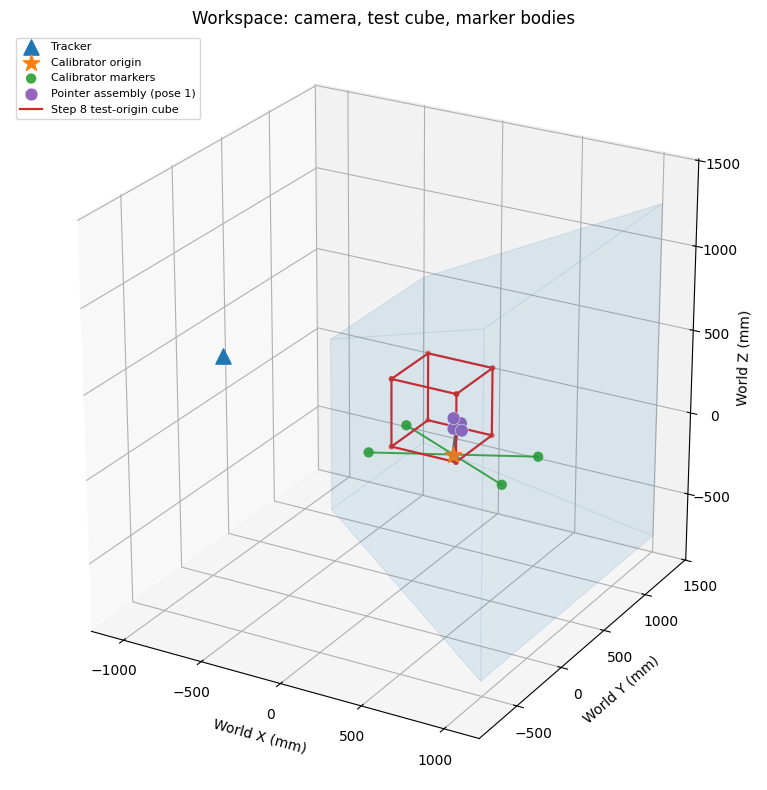

In [1186]:
%matplotlib inline

import matplotlib.pyplot as plt
from IPython.display import display
from functions.workspace_viz import plot_workspace

fig, ax, report = plot_workspace(
    F_tracker_approx,
    F_cal_approx,
    ptr_local_positions,
    ptr_tip_approx,
    cal_local_positions,
    show=False,
    show_detail=False
)

display(fig)
plt.close(fig)